<a href="https://colab.research.google.com/github/mohith890417/ml-lab/blob/main/Salary_Prediction_linear.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Import libraries


In [ ]:
pip install pandas seaborn scikit-learn

In [ ]:
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error,r2_score


In [ ]:
df = pd.read_csv("/content/Salary Data.csv")
df.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 375 entries, 0 to 374
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  373 non-null    float64
 1   Gender               373 non-null    object 
 2   Education Level      373 non-null    object 
 3   Job Title            373 non-null    object 
 4   Years of Experience  373 non-null    float64
 5   Salary               373 non-null    float64
dtypes: float64(3), object(3)
memory usage: 17.7+ KB


In [ ]:
df.dropna(inplace = True)
df.isnull().sum()

,0
Age,0
Gender,0
Education Level,0
Job Title,0
Years of Experience,0
Salary,0


In [ ]:
print("number of duplicate rows:", df.duplicated().sum())

number of duplicate rows: 49


In [ ]:
df.drop_duplicates(inplace=True)
print("number of duplicate rows:", df.duplicated().sum())

number of duplicate rows: 0


<Axes: ylabel='Age'>

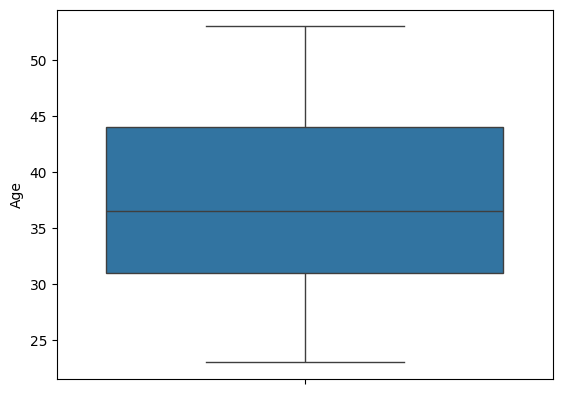

In [ ]:
sns.boxplot(df["Age"])

<Axes: ylabel='Years of Experience'>

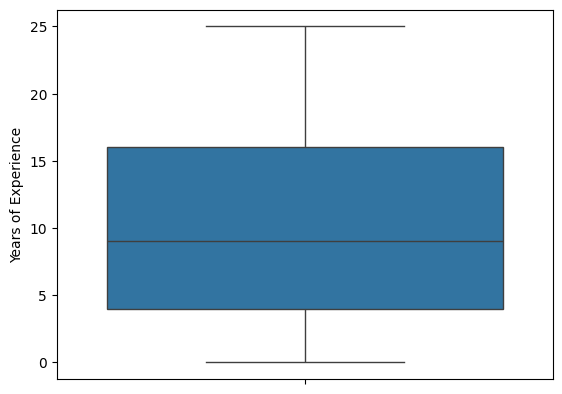

In [ ]:
sns.boxplot(df["Years of Experience"])

Apply encoding

In [ ]:
GE = LabelEncoder()
df["Gender_encoded"] = GE.fit_transform(df["Gender"])
df.head()


,Age,Gender,Education Level,Job Title,Years of Experience,Salary,Gender_encoded
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0,1
1,28.0,Female,Master's,Data Analyst,3.0,65000.0,0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0,1
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0,0
4,52.0,Male,Master's,Director,20.0,200000.0,1


In [ ]:
EL = LabelEncoder()
df["Education Level_encoder"] = EL.fit_transform(df["Education Level"])
df.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary,Gender_encoded,Education Level_encoder
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0,1,0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0,0,1
2,45.0,Male,PhD,Senior Manager,15.0,150000.0,1,2
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0,0,0
4,52.0,Male,Master's,Director,20.0,200000.0,1,1


Separate Dependent and Independent

In [ ]:
X=df[["Age","Years of Experience","Gender_encoded", "Education Level_encoder"]]
Y=df["Salary"]
print("Feature shape:", X.shape)
print("Target shape:", Y.shape)

Feature shape: (324, 4)
Target shape: (324,)


Split train and test

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)


In [ ]:
print("Records for training:",len(x_train))
print("Records for testing:",len(x_test))

Records for training: 259
Records for testing: 65


Apply scaling

In [ ]:
num_cols = ["Age", "Years of Experience"]
my_scaler = StandardScaler()
x_train[num_cols] = my_scaler.fit_transform(x_train[num_cols])
x_test[num_cols] = my_scaler.transform(x_test[num_cols])
print(x_train)

          Age  Years of Experience  Gender_encoded  Education Level_encoder
73  -1.324980            -1.226813               1                        0
182  0.877474             0.714752               0                        2
17   0.189207             0.266698               1                        2
24   0.464514             0.416049               1                        1
146  0.602167             0.864103               0                        2
..        ...                  ...             ...                      ...
189 -1.324980            -1.301488               1                        0
71   0.189207             0.117347               0                        0
106 -1.049673            -1.077461               0                        0
284 -0.361406            -0.181355               1                        0
102  1.565740             1.312156               0                        1

[259 rows x 4 columns]


Train the model

In [ ]:
salary_model = LinearRegression()
salary_model.fit(x_train,y_train)

LinearRegression()

Test

In [ ]:
y_predict = salary_model.predict(x_test)
result = pd.DataFrame(
    {
        "Actual":y_test,
        "predicted by_model":y_predict
    }
)
result.head(10)

,Actual,predicted by_model
132,100000.0,116136.607289
108,100000.0,124667.619930
137,50000.0,49205.367039
9,110000.0,127707.611369
181,105000.0,106510.651731
126,95000.0,99010.342045
221,45000.0,49269.607001
198,55000.0,57800.619642
279,180000.0,167515.403021
144,40000.0,43205.440089


In [ ]:
age = int(input("Enter your age: "))
years_of_experience = int(input("Enter your years of experience:"))
gender = int(input("Enter your gender (0 for female, 1 for male): "))
education_level = int(input("Enter your education level (0 for high school, 1 for bachelor's degree, 2 for master's degree, 3 for Ph.D.): "))

Enter your age: 24
Enter your years of experience:5
Enter your gender (0 for female, 1 for male): 0
Enter your education level (0 for high school, 1 for bachelor's degree, 2 for master's degree, 3 for Ph.D.): 2


In [ ]:
age = int(input("Enter your age: "))
years_of_experience = int(input("Enter your years of experience:"))
gender = int(input("Enter your gender (0 for female, 1 for male): "))
education_level = int(input("Enter your education level (0 for high school, 1 for bachelor's degree, 2 for master's degree, 3 for Ph.D.): "))

Enter your age: 23
Enter your years of experience:4
Enter your gender (0 for female, 1 for male): 0
Enter your education level (0 for high school, 1 for bachelor's degree, 2 for master's degree, 3 for Ph.D.): 0


In [ ]:
new_data = pd.DataFrame({"Age": [age], "Years of Experience": [years_of_experience], "Gender_encoded": [gender], "Education Level_encoder": [education_level]})
new_data[num_cols] = my_scaler.transform(new_data[num_cols])
predicted_salary = salary_model.predict(new_data)
print("Predicted Salary:", predicted_salary[0])

Predicted Salary: 646636.3072226566


In [ ]:
result = salary_model.predict([[age, years_of_experience, gender, education_level]])
print("Predicted salary:", result)

Predicted salary: [646636.30722266]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
